In [1]:
import pandas as pd 
import numpy as np

In [2]:
df = pd.read_csv("econocausal_enriched_synthetic_dataset.csv")
df.head()

,customer_id,age,income_bracket,urbanicity,region,tenure_months,historical_spend,recency_days,browsing_frequency,avg_session_duration_sec,...,days_since_last_campaign,marketing_contact_count_30d,discount_offered,discount_amount,purchased,basket_value_before_discount,revenue,cost_of_goods,marketing_cost,net_profit
0,100001,44,lower_middle,suburban,west,12,5502.94,4,5,168.9,...,23,3,10,91.95,0,919.46,0.00,0.00,4.50,-4.5
1,100002,39,lower_middle,suburban,west,7,4720.72,51,7,111.3,...,52,1,0,0.00,0,1500.40,0.00,0.00,1.50,-1.5
2,100003,26,lower_middle,rural,north,15,4656.31,12,6,343.7,...,3,2,0,0.00,0,453.77,0.00,0.00,3.00,-3.0
3,100004,25,low,rural,east,16,7174.15,13,10,136.4,...,40,2,10,133.99,1,1339.93,1205.94,905.95,136.99,163.0
4,100005,43,low,rural,west,22,2713.23,66,7,146.4,...,48,1,5,44.28,0,885.56,0.00,0.00,1.50,-1.5


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   customer_id                   20000 non-null  int64  
 1   age                           20000 non-null  int64  
 2   income_bracket                20000 non-null  object 
 3   urbanicity                    20000 non-null  object 
 4   region                        20000 non-null  object 
 5   tenure_months                 20000 non-null  int64  
 6   historical_spend              20000 non-null  float64
 7   recency_days                  20000 non-null  int64  
 8   browsing_frequency            20000 non-null  int64  
 9   avg_session_duration_sec      20000 non-null  float64
 10  cart_abandonment_rate         20000 non-null  float64
 11  support_tickets_count         20000 non-null  int64  
 12  email_open_rate               20000 non-null  float64
 13  p

In [4]:
df.shape

(20000, 40)

In [5]:
df.dtypes

customer_id                       int64
age                               int64
income_bracket                   object
urbanicity                       object
region                           object
tenure_months                     int64
historical_spend                float64
recency_days                      int64
browsing_frequency                int64
avg_session_duration_sec        float64
cart_abandonment_rate           float64
support_tickets_count             int64
email_open_rate                 float64
previous_discounts_accepted       int64
previous_purchases_12m            int64
avg_order_value                 float64
website_visits_30d                int64
mobile_app_user                   int64
loyalty_member                    int64
subscription_status              object
preferred_channel                object
product_category                 object
campaign_type                    object
day_of_week                      object
device_type                      object


In [6]:
df.isnull().sum()

customer_id                     0
age                             0
income_bracket                  0
urbanicity                      0
region                          0
tenure_months                   0
historical_spend                0
recency_days                    0
browsing_frequency              0
avg_session_duration_sec        0
cart_abandonment_rate           0
support_tickets_count           0
email_open_rate                 0
previous_discounts_accepted     0
previous_purchases_12m          0
avg_order_value                 0
website_visits_30d              0
mobile_app_user                 0
loyalty_member                  0
subscription_status             0
preferred_channel               0
product_category                0
campaign_type                   0
day_of_week                     0
device_type                     0
competitor_price_index          0
stock_availability              0
seasonality_index               0
customer_satisfaction           0
return_rate   

In [7]:
df.describe()

,customer_id,age,tenure_months,historical_spend,recency_days,browsing_frequency,avg_session_duration_sec,cart_abandonment_rate,support_tickets_count,email_open_rate,...,days_since_last_campaign,marketing_contact_count_30d,discount_offered,discount_amount,purchased,basket_value_before_discount,revenue,cost_of_goods,marketing_cost,net_profit
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,...,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,110000.500000,36.231450,31.931350,4697.311133,33.938450,8.013700,225.596390,0.408680,1.100150,0.454065,...,27.539800,2.008950,8.750000,138.057008,0.284450,1580.251461,412.845859,271.286065,43.776133,97.783661
std,5773.647028,10.576232,19.621513,2103.322637,33.691309,2.790269,130.314799,0.194218,1.057155,0.195867,...,27.925974,1.429571,7.395285,161.234871,0.451163,965.740539,809.771617,534.537467,109.987695,254.100120
min,100001.000000,18.000000,1.000000,603.190000,0.000000,0.000000,10.000000,0.001000,0.000000,0.002000,...,0.000000,0.000000,0.000000,0.000000,0.000000,100.000000,0.000000,0.000000,0.000000,-791.900000
25%,105000.750000,28.000000,17.000000,3166.132500,9.000000,6.000000,130.300000,0.258000,0.000000,0.305000,...,8.000000,1.000000,3.750000,4.020000,0.000000,882.815000,0.000000,0.000000,1.500000,-4.500000
50%,110000.500000,36.000000,28.000000,4390.025000,23.000000,8.000000,201.750000,0.395000,1.000000,0.448000,...,19.000000,2.000000,7.500000,90.640000,0.000000,1371.180000,0.000000,0.000000,3.000000,-1.500000
75%,115000.250000,43.000000,43.000000,5876.940000,48.000000,10.000000,294.200000,0.548000,2.000000,0.598000,...,39.000000,3.000000,12.500000,195.025000,1.000000,2060.380000,546.897500,357.875000,7.500000,0.000000
max,120000.000000,75.000000,120.000000,19154.330000,180.000000,20.000000,1200.000000,0.977000,7.000000,0.969000,...,180.000000,11.000000,20.000000,1596.940000,1.000000,9652.160000,8204.620000,6154.590000,1596.940000,2937.120000


In [8]:
for col in df.select_dtypes(include=['object']).columns:
    print(f"column: '{col}' ")
    print(df[col].unique())

column: 'income_bracket' 
['lower_middle' 'low' 'high' 'upper_middle']
column: 'urbanicity' 
['suburban' 'rural' 'urban']
column: 'region' 
['west' 'north' 'east' 'central' 'south']
column: 'subscription_status' 
['premium' 'none' 'basic']
column: 'preferred_channel' 
['email' 'web' 'sms' 'push']
column: 'product_category' 
['beauty' 'home' 'sports' 'electronics' 'fashion']
column: 'campaign_type' 
['seasonal' 'new_product' 'win_back' 'loyalty']
column: 'day_of_week' 
['Mon' 'Tue' 'Thu' 'Sun' 'Fri' 'Sat' 'Wed']
column: 'device_type' 
['mobile' 'desktop' 'tablet']
column: 'stock_availability' 
['in_stock' 'low_stock']


# Exploratory Data Analysis

In [9]:
df

,customer_id,age,income_bracket,urbanicity,region,tenure_months,historical_spend,recency_days,browsing_frequency,avg_session_duration_sec,...,days_since_last_campaign,marketing_contact_count_30d,discount_offered,discount_amount,purchased,basket_value_before_discount,revenue,cost_of_goods,marketing_cost,net_profit
0,100001,44,lower_middle,suburban,west,12,5502.94,4,5,168.9,...,23,3,10,91.95,0,919.46,0.00,0.00,4.50,-4.50
1,100002,39,lower_middle,suburban,west,7,4720.72,51,7,111.3,...,52,1,0,0.00,0,1500.40,0.00,0.00,1.50,-1.50
2,100003,26,lower_middle,rural,north,15,4656.31,12,6,343.7,...,3,2,0,0.00,0,453.77,0.00,0.00,3.00,-3.00
3,100004,25,low,rural,east,16,7174.15,13,10,136.4,...,40,2,10,133.99,1,1339.93,1205.94,905.95,136.99,163.00
4,100005,43,low,rural,west,22,2713.23,66,7,146.4,...,48,1,5,44.28,0,885.56,0.00,0.00,1.50,-1.50
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,119996,28,low,suburban,central,22,8162.06,13,10,48.6,...,0,1,5,93.37,0,1867.46,0.00,0.00,1.50,-1.50
19996,119997,41,low,suburban,south,49,3263.97,13,13,208.9,...,109,2,10,399.38,0,3993.76,0.00,0.00,3.00,-3.00
19997,119998,33,lower_middle,urban,east,23,8026.06,15,16,101.2,...,11,2,5,62.22,1,1244.48,1182.26,778.52,65.22,338.52
19998,119999,34,upper_middle,suburban,north,61,5882.20,2,15,293.1,...,12,1,5,65.33,1,1306.65,1241.32,757.53,66.83,416.96


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

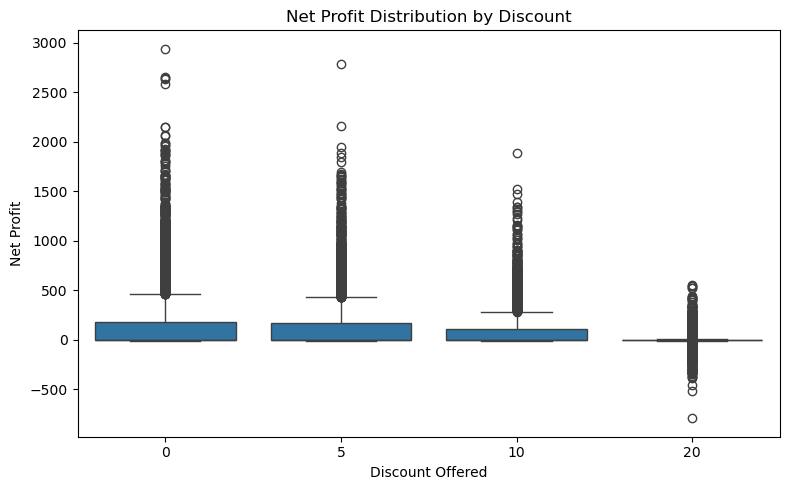

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="discount_offered", y="net_profit")

plt.title("Net Profit Distribution by Discount")
plt.xlabel("Discount Offered")
plt.ylabel("Net Profit")
plt.tight_layout()
plt.show()


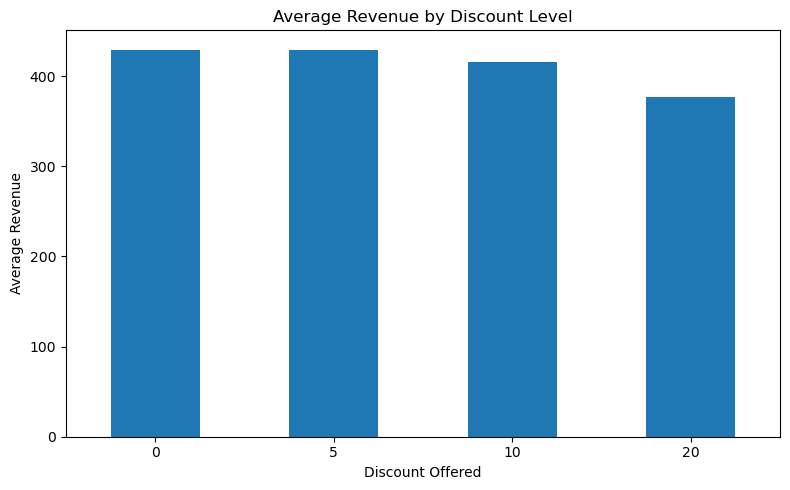

In [12]:
avg_revenue = df.groupby("discount_offered")["revenue"].mean()
plt.figure(figsize=(8, 5))
avg_revenue.plot(kind="bar")

plt.title("Average Revenue by Discount Level")
plt.xlabel("Discount Offered")
plt.ylabel("Average Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


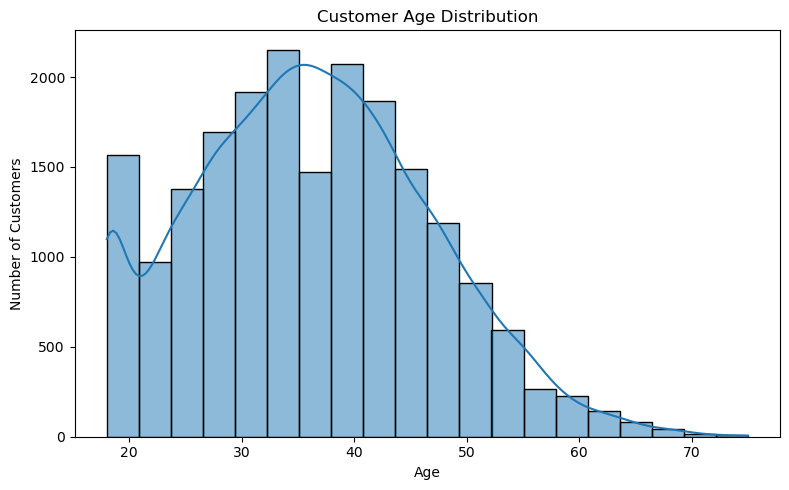

In [13]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


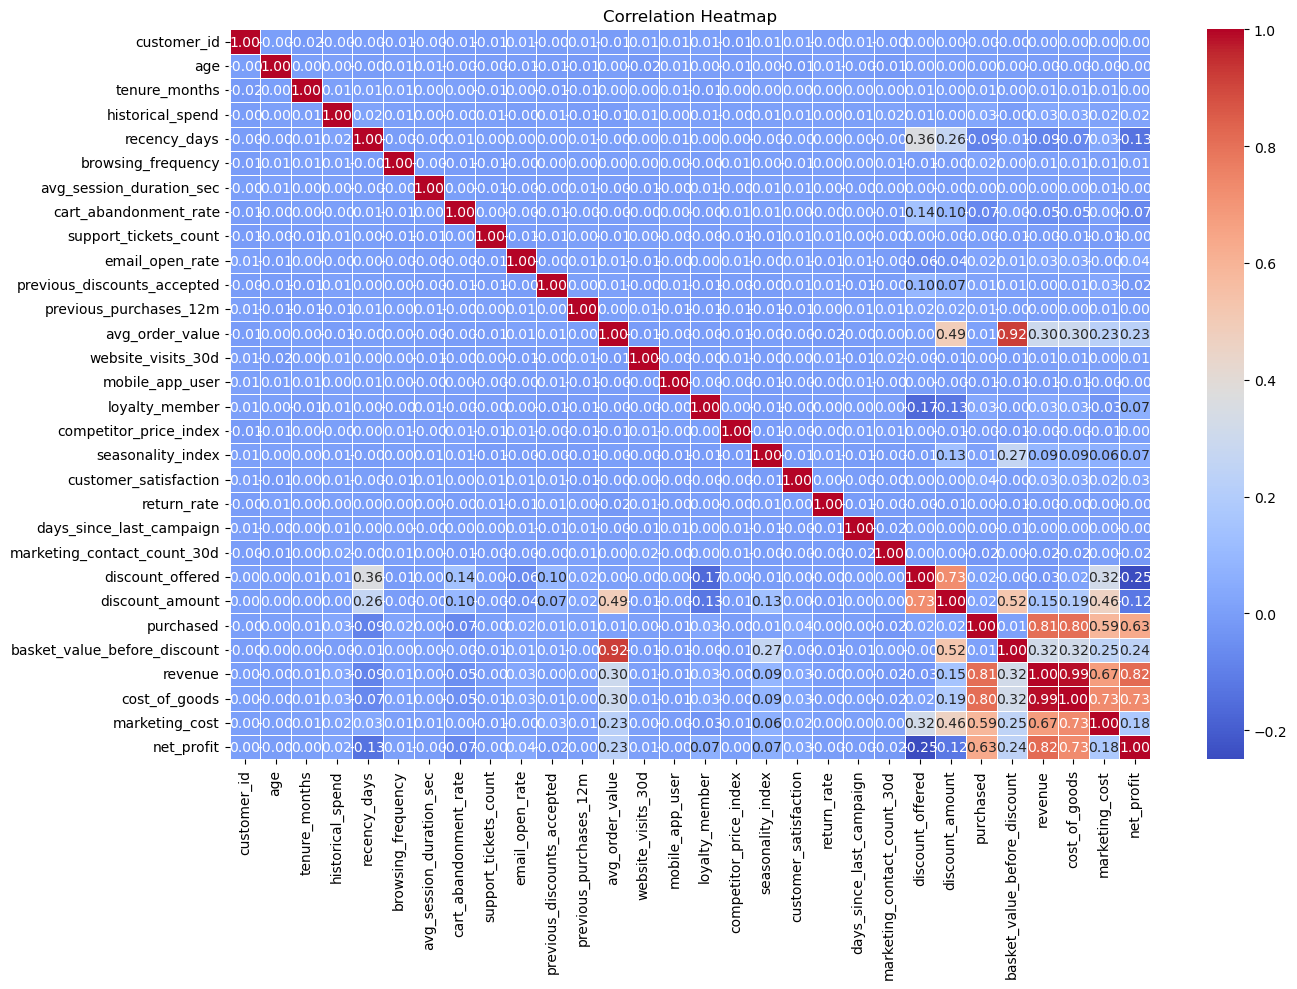

In [14]:
numeric_df = df.select_dtypes(include="number")
plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


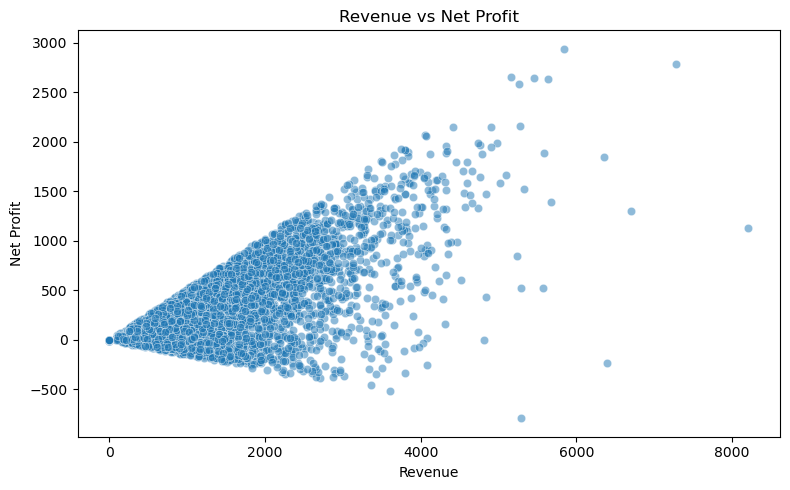

In [15]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="revenue",
    y="net_profit",
    alpha=0.5
)

plt.title("Revenue vs Net Profit")
plt.xlabel("Revenue")
plt.ylabel("Net Profit")
plt.tight_layout()
plt.show()


In [16]:
df.head(5)

,customer_id,age,income_bracket,urbanicity,region,tenure_months,historical_spend,recency_days,browsing_frequency,avg_session_duration_sec,...,days_since_last_campaign,marketing_contact_count_30d,discount_offered,discount_amount,purchased,basket_value_before_discount,revenue,cost_of_goods,marketing_cost,net_profit
0,100001,44,lower_middle,suburban,west,12,5502.94,4,5,168.9,...,23,3,10,91.95,0,919.46,0.00,0.00,4.50,-4.5
1,100002,39,lower_middle,suburban,west,7,4720.72,51,7,111.3,...,52,1,0,0.00,0,1500.40,0.00,0.00,1.50,-1.5
2,100003,26,lower_middle,rural,north,15,4656.31,12,6,343.7,...,3,2,0,0.00,0,453.77,0.00,0.00,3.00,-3.0
3,100004,25,low,rural,east,16,7174.15,13,10,136.4,...,40,2,10,133.99,1,1339.93,1205.94,905.95,136.99,163.0
4,100005,43,low,rural,west,22,2713.23,66,7,146.4,...,48,1,5,44.28,0,885.56,0.00,0.00,1.50,-1.5


In [17]:
X = df[
[
    "age","income_bracket","urbanicity","region",
    "tenure_months","historical_spend","recency_days",
    "browsing_frequency","avg_session_duration_sec",
    "cart_abandonment_rate","support_tickets_count",
    "email_open_rate","previous_discounts_accepted",
    "previous_purchases_12m","avg_order_value",
    "website_visits_30d","mobile_app_user","loyalty_member",
    "subscription_status","preferred_channel","product_category",
    "campaign_type","day_of_week","device_type",
    "competitor_price_index","stock_availability","seasonality_index",
    "customer_satisfaction","return_rate","days_since_last_campaign","marketing_contact_count_30d"
]]
X.head(5)

,age,income_bracket,urbanicity,region,tenure_months,historical_spend,recency_days,browsing_frequency,avg_session_duration_sec,cart_abandonment_rate,...,campaign_type,day_of_week,device_type,competitor_price_index,stock_availability,seasonality_index,customer_satisfaction,return_rate,days_since_last_campaign,marketing_contact_count_30d
0,44,lower_middle,suburban,west,12,5502.94,4,5,168.9,0.334,...,seasonal,Mon,mobile,0.938,in_stock,1.192,3.99,0.377,23,3
1,39,lower_middle,suburban,west,7,4720.72,51,7,111.3,0.058,...,seasonal,Tue,desktop,0.909,in_stock,1.111,3.59,0.221,52,1
2,26,lower_middle,rural,north,15,4656.31,12,6,343.7,0.333,...,new_product,Thu,mobile,1.231,in_stock,1.277,4.03,0.125,3,2
3,25,low,rural,east,16,7174.15,13,10,136.4,0.308,...,new_product,Sun,mobile,1.170,in_stock,1.014,3.77,0.314,40,2
4,43,low,rural,west,22,2713.23,66,7,146.4,0.227,...,seasonal,Mon,tablet,1.076,in_stock,0.830,3.09,0.006,48,1


In [18]:
X.shape

(20000, 31)

In [19]:
X.dtypes


age                              int64
income_bracket                  object
urbanicity                      object
region                          object
tenure_months                    int64
historical_spend               float64
recency_days                     int64
browsing_frequency               int64
avg_session_duration_sec       float64
cart_abandonment_rate          float64
support_tickets_count            int64
email_open_rate                float64
previous_discounts_accepted      int64
previous_purchases_12m           int64
avg_order_value                float64
website_visits_30d               int64
mobile_app_user                  int64
loyalty_member                   int64
subscription_status             object
preferred_channel               object
product_category                object
campaign_type                   object
day_of_week                     object
device_type                     object
competitor_price_index         float64
stock_availability       

In [20]:
T = df["discount_offered"]
y = df["purchased"]
y.head(10)

0    0
1    0
2    0
3    1
4    0
5    0
6    0
7    1
8    0
9    1
Name: purchased, dtype: int64

In [21]:
T.head(10)

0    10
1     0
2     0
3    10
4     5
5     0
6     0
7    10
8     0
9    10
Name: discount_offered, dtype: int64

In [22]:
X.head()

,age,income_bracket,urbanicity,region,tenure_months,historical_spend,recency_days,browsing_frequency,avg_session_duration_sec,cart_abandonment_rate,...,campaign_type,day_of_week,device_type,competitor_price_index,stock_availability,seasonality_index,customer_satisfaction,return_rate,days_since_last_campaign,marketing_contact_count_30d
0,44,lower_middle,suburban,west,12,5502.94,4,5,168.9,0.334,...,seasonal,Mon,mobile,0.938,in_stock,1.192,3.99,0.377,23,3
1,39,lower_middle,suburban,west,7,4720.72,51,7,111.3,0.058,...,seasonal,Tue,desktop,0.909,in_stock,1.111,3.59,0.221,52,1
2,26,lower_middle,rural,north,15,4656.31,12,6,343.7,0.333,...,new_product,Thu,mobile,1.231,in_stock,1.277,4.03,0.125,3,2
3,25,low,rural,east,16,7174.15,13,10,136.4,0.308,...,new_product,Sun,mobile,1.170,in_stock,1.014,3.77,0.314,40,2
4,43,low,rural,west,22,2713.23,66,7,146.4,0.227,...,seasonal,Mon,tablet,1.076,in_stock,0.830,3.09,0.006,48,1


## apply one-hot encoding to categorical features

In [23]:
X = pd.get_dummies(X,
    columns=X.select_dtypes(include=["object","category"]).columns,
    drop_first=True,dtype=int
)
X.head()

,age,tenure_months,historical_spend,recency_days,browsing_frequency,avg_session_duration_sec,cart_abandonment_rate,support_tickets_count,email_open_rate,previous_discounts_accepted,...,campaign_type_win_back,day_of_week_Mon,day_of_week_Sat,day_of_week_Sun,day_of_week_Thu,day_of_week_Tue,day_of_week_Wed,device_type_mobile,device_type_tablet,stock_availability_low_stock
0,44,12,5502.94,4,5,168.9,0.334,0,0.435,2,...,0,1,0,0,0,0,0,1,0,0
1,39,7,4720.72,51,7,111.3,0.058,1,0.342,1,...,0,0,0,0,0,1,0,0,0,0
2,26,15,4656.31,12,6,343.7,0.333,2,0.105,4,...,0,0,0,0,1,0,0,1,0,0
3,25,16,7174.15,13,10,136.4,0.308,0,0.835,1,...,0,0,0,1,0,0,0,1,0,0
4,43,22,2713.23,66,7,146.4,0.227,0,0.675,2,...,0,1,0,0,0,0,0,0,1,0


In [24]:
X.shape

(20000, 51)

In [25]:
X.dtypes

age                               int64
tenure_months                     int64
historical_spend                float64
recency_days                      int64
browsing_frequency                int64
avg_session_duration_sec        float64
cart_abandonment_rate           float64
support_tickets_count             int64
email_open_rate                 float64
previous_discounts_accepted       int64
previous_purchases_12m            int64
avg_order_value                 float64
website_visits_30d                int64
mobile_app_user                   int64
loyalty_member                    int64
competitor_price_index          float64
seasonality_index               float64
customer_satisfaction           float64
return_rate                     float64
days_since_last_campaign          int64
marketing_contact_count_30d       int64
income_bracket_low                int64
income_bracket_lower_middle       int64
income_bracket_upper_middle       int64
urbanicity_suburban               int64


In [26]:
from sklearn.model_selection import train_test_split

In [27]:
X_train,X_test,T_train,T_test,y_train,y_test=train_test_split(
    X,T,y,
    test_size=0.2,
    random_state=42,
    stratify=T
)

In [28]:
X_train

,age,tenure_months,historical_spend,recency_days,browsing_frequency,avg_session_duration_sec,cart_abandonment_rate,support_tickets_count,email_open_rate,previous_discounts_accepted,...,campaign_type_win_back,day_of_week_Mon,day_of_week_Sat,day_of_week_Sun,day_of_week_Thu,day_of_week_Tue,day_of_week_Wed,device_type_mobile,device_type_tablet,stock_availability_low_stock
15692,35,26,15477.52,77,9,98.8,0.197,2,0.311,2,...,1,0,0,0,0,1,0,1,0,0
4651,34,10,5363.52,13,6,292.3,0.770,1,0.871,2,...,1,0,0,0,1,0,0,0,0,0
10478,30,42,1561.47,65,14,161.9,0.646,1,0.441,2,...,0,0,0,0,0,1,0,0,0,0
10174,29,41,3200.74,33,11,217.8,0.443,2,0.603,1,...,0,0,0,1,0,0,0,0,0,0
15273,44,23,2373.65,85,12,266.4,0.375,0,0.192,2,...,1,0,1,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11118,32,42,2607.83,23,8,285.0,0.734,0,0.453,1,...,0,0,0,0,1,0,0,1,0,0
220,43,22,6508.17,41,10,217.3,0.442,1,0.467,0,...,0,0,0,0,0,0,0,0,0,0
9150,36,56,6652.46,2,8,244.9,0.247,0,0.330,3,...,0,0,0,0,0,1,0,0,0,0
2132,61,27,2015.09,4,9,247.2,0.128,2,0.753,2,...,0,0,0,0,0,0,1,1,0,1


In [29]:
X_train.shape

(16000, 51)

In [30]:
X_test

,age,tenure_months,historical_spend,recency_days,browsing_frequency,avg_session_duration_sec,cart_abandonment_rate,support_tickets_count,email_open_rate,previous_discounts_accepted,...,campaign_type_win_back,day_of_week_Mon,day_of_week_Sat,day_of_week_Sun,day_of_week_Thu,day_of_week_Tue,day_of_week_Wed,device_type_mobile,device_type_tablet,stock_availability_low_stock
11888,33,40,3022.79,10,8,198.8,0.431,1,0.346,3,...,0,0,0,0,0,0,0,1,0,0
4533,30,3,5760.68,6,11,176.6,0.200,0,0.398,3,...,0,0,0,0,0,0,1,1,0,0
12012,24,11,9021.46,12,15,167.9,0.516,1,0.286,0,...,1,0,1,0,0,0,0,1,0,0
1190,57,39,4140.35,12,6,103.0,0.391,3,0.625,1,...,1,0,0,0,0,0,1,1,0,0
17818,26,9,2892.13,8,6,36.0,0.249,2,0.663,1,...,0,0,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19187,30,27,3225.72,19,4,166.2,0.889,2,0.636,0,...,0,0,0,0,1,0,0,0,1,0
19005,27,18,3376.83,33,4,121.9,0.259,3,0.590,2,...,1,0,1,0,0,0,0,1,0,0
9697,42,74,4368.72,13,11,156.6,0.614,4,0.565,0,...,0,0,1,0,0,0,0,0,0,0
19470,52,19,3787.84,9,6,210.3,0.606,2,0.207,3,...,1,0,0,0,0,0,0,0,1,1


In [31]:
X_test.shape

(4000, 51)

In [32]:
T_test.shape

(4000,)

In [33]:
T_train.shape

(16000,)

In [34]:
y_train.shape

(16000,)

In [35]:
y_test.shape

(4000,)

In [36]:
T_train.value_counts().sort_index()

discount_offered
0     4000
5     4000
10    4000
20    4000
Name: count, dtype: int64

In [37]:
T_test.value_counts().sort_index()


discount_offered
0     1000
5     1000
10    1000
20    1000
Name: count, dtype: int64

In [39]:
pip install econml

In [40]:
from econml.dml import CausalForestDML
from sklearn.ensemble import RandomForestRegressor,RandomForestClassifier

In [41]:
dml_model=CausalForestDML(
    model_y=RandomForestRegressor(
        n_estimators=100,min_samples_leaf=10,random_state=42
    ),
    model_t=RandomForestClassifier(
    n_estimators=100,min_samples_leaf=10,random_state=42
),
discrete_treatment=True,
cv=3,
n_estimators=100,
random_state=42
)

In [42]:
dml_model.fit(
    Y=np.asarray(y_train).ravel(),
    T=np.asarray(T_train).ravel(),
    X=X_train
)


In [43]:
ite_10=dml_model.effect(
    X_test,T0=0,T1=10
)
print("Average estimated causal effect:", ite_10.mean())

Average estimated causal effect: 0.04643287977016722


In [44]:
ite_10.min()

np.float64(-0.1574433036157057)

In [45]:
ite_10.max()

np.float64(0.22209064189812075)

In [49]:
results = pd.DataFrame(
    {
    "actual_discount": T_test.to_numpy(),
    "actual_purchase": y_test.to_numpy(),
    "estimated_effect_10_vs_0": np.asarray(ite_10).ravel()
})
display(results.head(10))
results.to_csv(
    "econocausal_test_customer_effects.csv",
    index=False
)


,actual_discount,actual_purchase,estimated_effect_10_vs_0
0,20,1,0.149694
1,0,0,-0.022916
2,10,0,0.070969
3,0,0,0.015990
4,5,1,0.030425
5,20,0,0.048658
6,0,1,0.089973
7,0,1,-0.019138
8,0,0,0.040236
9,10,0,0.059549


In [50]:
eval_df=pd.DataFrame({
    "treatment":T_test.to_numpy(),
    "outcome":y_test.to_numpy(),
    "estimated_ite":np.asarray(ite_10).ravel()
})

eval_df=eval_df[
    eval_df["treatment"].isin([0, 10])
].copy()


In [54]:
eval_df["treatment"]=(
    eval_df["treatment"]==10
).astype(int)

print("evaluation rows:-",len(eval_df))

print("\nTreatment counts:-")
print(eval_df["treatment"].value_counts())

print("\nPurchase rates:-")
print(eval_df.groupby("treatment")["outcome"].mean())

evaluation rows:- 2000
Treatment counts:-
treatment
0    2000
Name: count, dtype: int64
Purchase rates:-
treatment
0    0.2915
Name: outcome, dtype: float64
